In [1]:
!pip install -q transformers datasets huggingface_hub timm pycocotools
!pip install -q albumentations opencv-python matplotlib seaborn

In [2]:
import os

PROJECT_DIR = "/content/Underwater_Trash_Project"

folders = [
    "Dataset",
    "Models",
    "Results",
    "Outputs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

print("\nProject Location:", PROJECT_DIR)

Project folders created successfully!

Project Location: /content/Underwater_Trash_Project


In [3]:
from huggingface_hub import snapshot_download
import os

DATASET_DIR = "/content/Underwater_Trash_Project/Dataset"

print("Downloading dataset...")

download_path = snapshot_download(
    repo_id="karanwxlia/Underwater-Trash-Detection-Dataset",
    repo_type="dataset",
    local_dir=DATASET_DIR
)

print("Dataset downloaded successfully!")
print("Location:", download_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Dataset downloaded successfully!
Location: /content/Underwater_Trash_Project/Dataset


In [4]:
import os

for root, dirs, files in os.walk(DATASET_DIR):

    level = root.replace(DATASET_DIR, '').count(os.sep)

    if level <= 2:

        print("\n" + "  " * level + os.path.basename(root) + "/")

        for file in files[:10]:
            print("  " * (level + 1) + file)


Dataset/
  README.md
  .gitattributes
  tensorflowOD_format.zip
  YOLO_format.zip
  COCO_format.zip

  .cache/

    huggingface/
      CACHEDIR.TAG
      .gitignore


In [5]:
import os

image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total Images:", len(image_files))
print("\nFirst 10 Images:")

for img in image_files[:10]:
    print(img)

Total Images: 0

First 10 Images:


In [6]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 10))

for i in range(min(6, len(image_files))):
    img = Image.open(image_files[i]).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Image {i+1}")

plt.tight_layout()
plt.show()

<Figure size 1500x1000 with 0 Axes>

In [7]:
for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith((".json", ".txt", ".xml", ".csv")):
            print(os.path.join(root, file))

/content/Underwater_Trash_Project/Dataset/.cache/huggingface/trees/294d20f28d5adf19b28e9729e96c852e49e42555.json


In [8]:
import os
import json

json_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(".json"):
            json_files.append(os.path.join(root, file))

print("JSON Files Found:", len(json_files))

for file in json_files[:5]:
    print(file)

JSON Files Found: 1
/content/Underwater_Trash_Project/Dataset/.cache/huggingface/trees/294d20f28d5adf19b28e9729e96c852e49e42555.json


In [9]:
if json_files:

    annotation_file = json_files[0]

    with open(annotation_file, "r") as f:
        data = json.load(f)

    print("Annotation File:", annotation_file)
    print("\nJSON Structure:")

    if isinstance(data, dict):
        print("Keys:", data.keys())

    print("\nSample Data:")
    print(str(data)[:2000])

else:
    print("No JSON annotation files found.")

Annotation File: /content/Underwater_Trash_Project/Dataset/.cache/huggingface/trees/294d20f28d5adf19b28e9729e96c852e49e42555.json

JSON Structure:
Keys: dict_keys(['format_version', 'files'])

Sample Data:
{'format_version': 1, 'files': {'.gitattributes': {'size': 2461, 'blob_id': '1ef325f1b111266a6b26e0196871bd78baa8c2f3'}, 'COCO_format.zip': {'size': 77897909, 'blob_id': 'd58e4c708f7d7f416885cfc46e26abdf8ff73f6e', 'lfs_sha256': '570bf4abaa644d69e55a8ca91bcb5d90ff7815b0211f940d5e8ac79cd0b2280b', 'lfs_size': 77897909, 'xet_hash': '03ca0da1732414d41fa6247effbf221e4e5c25a01500c5f146156ee6a0022a30'}, 'README.md': {'size': 1970, 'blob_id': 'af99ef90f24fbd1cc102898c6fb5013e20c98081'}, 'YOLO_format.zip': {'size': 77996518, 'blob_id': '0a762bd3195be76f11decc46402e69bd78d3975d', 'lfs_sha256': 'b04a28fe9a7b3769d6650490745d223780fd650802852b538c54c3a77cf29c28', 'lfs_size': 77996518, 'xet_hash': 'a47edbb8d934760758ce990a39c917588d758dbdbcb3cbcb9b40ced93e4b93cc'}, 'tensorflowOD_format.zip': {'size

In [10]:
import os

DATASET_DIR = "/content/Underwater_Trash_Project/Dataset"

zip_path = os.path.join(DATASET_DIR, "COCO_format.zip")

print("Checking dataset ZIP...")

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size:", round(os.path.getsize(zip_path)/1024/1024, 2), "MB")

Checking dataset ZIP...
ZIP exists: True
ZIP size: 74.29 MB


In [11]:
from huggingface_hub import hf_hub_download
import os

DATASET_DIR = "/content/Underwater_Trash_Project/Dataset"

zip_path = hf_hub_download(
    repo_id="karanwxlia/Underwater-Trash-Detection-Dataset",
    filename="COCO_format.zip",
    repo_type="dataset"
)

print("Download successful!")
print("File path:", zip_path)
print("File size:", round(os.path.getsize(zip_path)/1024/1024, 2), "MB")

COCO_format.zip: reconstructing file:   0%|          |  0.00B / 77.9MB            

COCO_format.zip: downloading bytes:           |  0.00B            

Download successful!
File path: /root/.cache/huggingface/hub/datasets--karanwxlia--Underwater-Trash-Detection-Dataset/snapshots/294d20f28d5adf19b28e9729e96c852e49e42555/COCO_format.zip
File size: 74.29 MB


In [12]:
import zipfile
import os

extract_path = "/content/Underwater_Trash_Project/Dataset/COCO_Extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("COCO Dataset extracted successfully!")

COCO Dataset extracted successfully!


In [13]:
import os

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 3:
        print("\n" + "  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)


COCO_Extracted/
  README.roboflow.txt
  README.dataset.txt

  test/
    vid_000158_frame0000057_jpg.rf.7e06d9cad20245264a1088caddbace32.jpg
    obj0304_frame0000034_jpg.rf.f03bf9d957630b3cbe99b2d8de2ffb64.jpg
    bio0012_frame0000135_jpg.rf.e87510a6cb23abf08779c3d534453da1.jpg
    bio0016_frame0000394_jpg.rf.55ab446536fff80e68a6c029e4705162.jpg
    obj1076_frame0000009_jpg.rf.1409802982dc33745daa531d7bd69a14.jpg

  valid/
    obj0313_frame0000015_jpg.rf.f1f1b5ef38bdc66f20cb61fcb7d964a0.jpg
    6_jpeg_jpg.rf.60c6dede5f773482fd520dd52c223022.jpg
    obj0317_frame0000054_jpg.rf.4555e8ebf29ca3776b046feac697a7bc.jpg
    vid_000112_frame0000016_jpg.rf.bd2f931a19701e2d65acd43247687564.jpg
    vid_000550_frame0000001_jpg.rf.a44d2cbe0784da0570df3a67d6fb042d.jpg

  train/
    frame_01050_png_jpg.rf.1b83c9388480da3b04dd36a6654e4a10.jpg
    bio0016_frame0000285_jpg.rf.5d26d046e72ea1b37eddf6664b9f1627.jpg
    bio0015_frame0000540_jpg.rf.502c42f77211d41ff6302a6de888cdc3.jpg
    bio0002_frame0000591

In [14]:
import os

image_extensions = (".jpg", ".jpeg", ".png", ".webp")

image_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total Images:", len(image_files))
print("\nFirst 10 Images:")

for img in image_files[:10]:
    print(img)

Total Images: 9576

First 10 Images:
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/vid_000158_frame0000057_jpg.rf.7e06d9cad20245264a1088caddbace32.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/obj0304_frame0000034_jpg.rf.f03bf9d957630b3cbe99b2d8de2ffb64.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/bio0012_frame0000135_jpg.rf.e87510a6cb23abf08779c3d534453da1.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/bio0016_frame0000394_jpg.rf.55ab446536fff80e68a6c029e4705162.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/obj1076_frame0000009_jpg.rf.1409802982dc33745daa531d7bd69a14.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/obj1523_frame0000049_jpg.rf.ca3d4ca53acead931b6a45f03a962579.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/obj1061_frame0000064_jpg.rf.ff651e219172e4a94efe88ed80217443.jpg
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/vid_00012

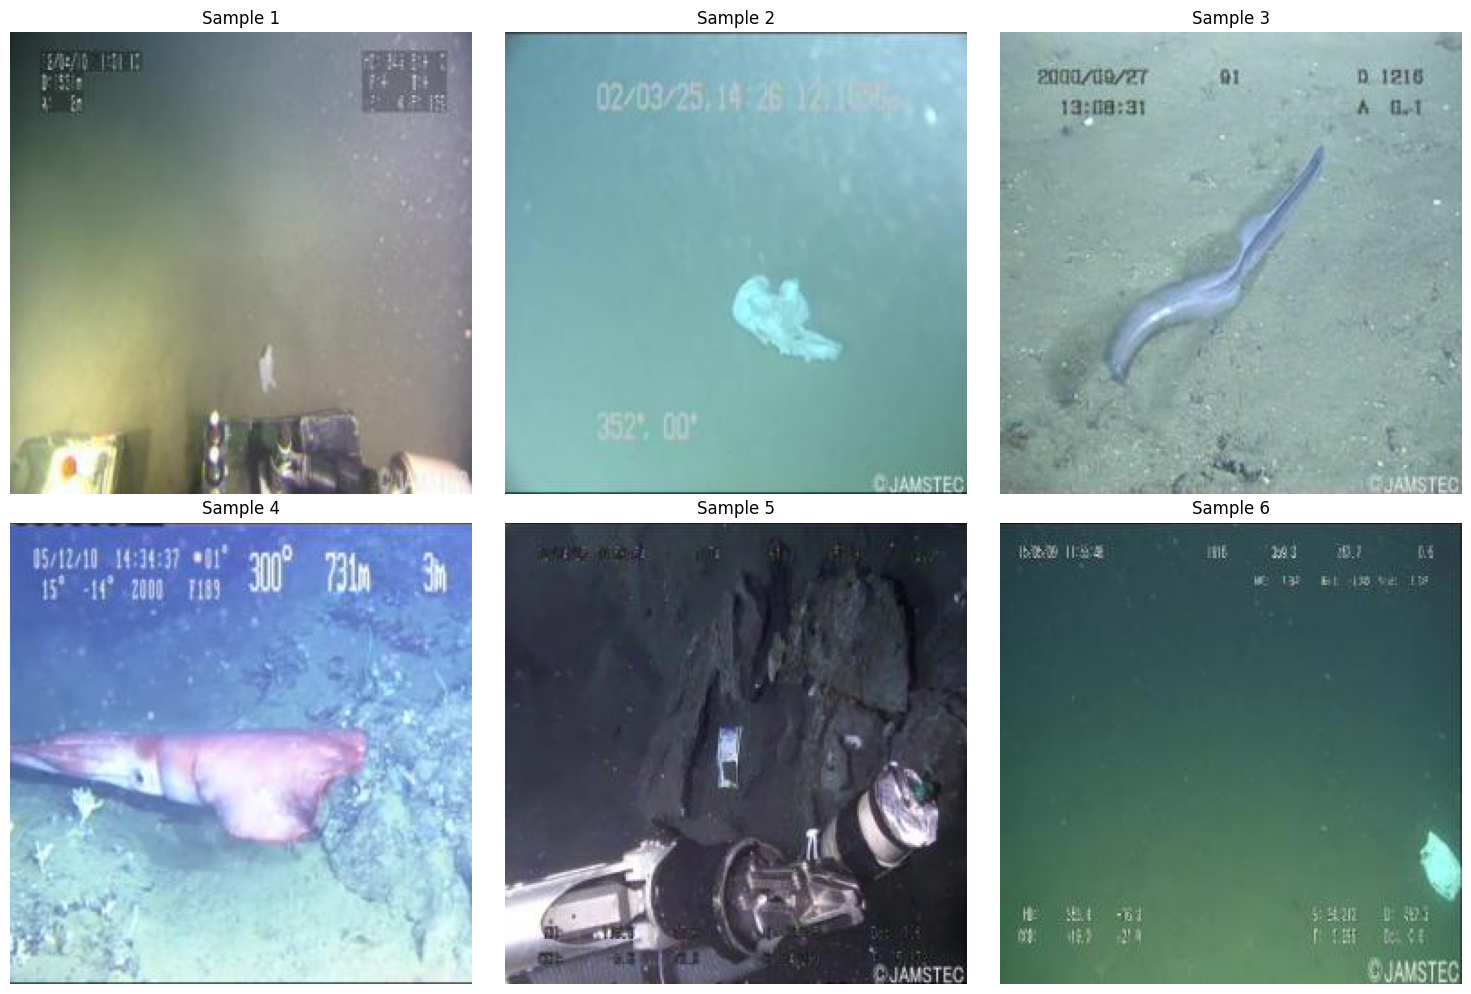

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

if len(image_files) > 0:

    plt.figure(figsize=(15, 10))

    for i in range(min(6, len(image_files))):

        img = Image.open(image_files[i]).convert("RGB")

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"Sample {i+1}")

    plt.tight_layout()
    plt.show()

else:
    print("No images found.")

In [16]:
annotation_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith((".json", ".xml", ".txt")):
            annotation_files.append(os.path.join(root, file))

print("Annotation files found:", len(annotation_files))

for file in annotation_files[:20]:
    print(file)

Annotation files found: 5
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/README.roboflow.txt
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/README.dataset.txt
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/_annotations.coco.json
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/valid/_annotations.coco.json
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/train/_annotations.coco.json


In [17]:
import os

coco_json_files = []

for root, dirs, files in os.walk(extract_path):
    dirs[:] = [d for d in dirs if d != ".cache"]

    for file in files:
        if file.lower().endswith(".json"):
            full_path = os.path.join(root, file)

            if "annotation" in file.lower() or "instances" in file.lower():
                coco_json_files.append(full_path)

print("Possible COCO annotation files:", len(coco_json_files))

for file in coco_json_files:
    print(file)

Possible COCO annotation files: 3
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/_annotations.coco.json
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/valid/_annotations.coco.json
/content/Underwater_Trash_Project/Dataset/COCO_Extracted/train/_annotations.coco.json


In [18]:
import json

if coco_json_files:

    annotation_path = coco_json_files[0]

    with open(annotation_path, "r") as f:
        annotation_data = json.load(f)

    print("Annotation file:", annotation_path)
    print("Keys:", annotation_data.keys())

    print("\nImages:", len(annotation_data.get("images", [])))
    print("Annotations:", len(annotation_data.get("annotations", [])))
    print("Categories:", annotation_data.get("categories", []))

else:
    print("COCO annotation file not found.")

Annotation file: /content/Underwater_Trash_Project/Dataset/COCO_Extracted/test/_annotations.coco.json
Keys: dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])

Images: 473
Annotations: 719
Categories: [{'id': 0, 'name': 'trash', 'supercategory': 'none'}, {'id': 1, 'name': 'Bio', 'supercategory': 'trash'}, {'id': 2, 'name': 'Rov', 'supercategory': 'trash'}, {'id': 3, 'name': 'Trash', 'supercategory': 'trash'}]


In [19]:
categories = annotation_data["categories"]

print("Dataset Classes:\n")

for category in categories:
    print(
        "ID:", category["id"],
        "| Name:", category["name"]
    )

Dataset Classes:

ID: 0 | Name: trash
ID: 1 | Name: Bio
ID: 2 | Name: Rov
ID: 3 | Name: Trash


In [21]:
from collections import Counter

annotation_counts = Counter(
    annotation["category_id"]
    for annotation in annotation_data["annotations"]
)

print(annotation_counts)

Counter({3: 481, 1: 132, 2: 106})


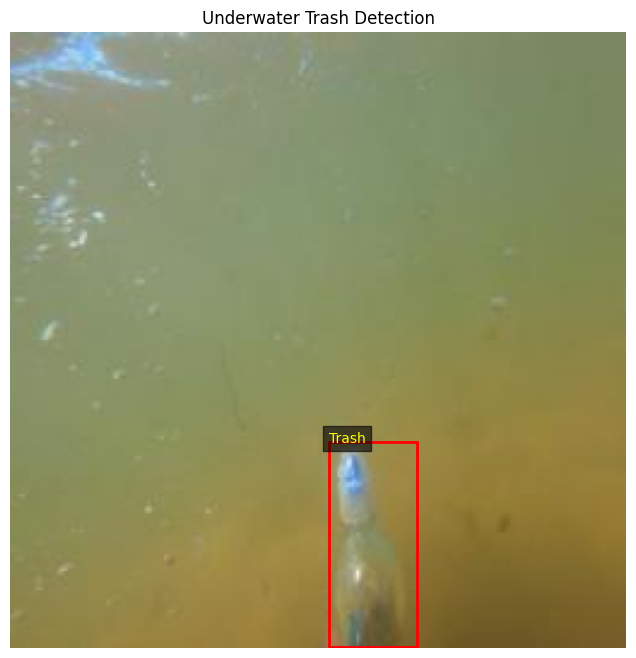

Image: frame_01995_png_jpg.rf.808a1032e3f67c4cb850dbf8bb68f03e.jpg
Objects: 1


In [30]:
# Visualize COCO Bounding Boxes

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

img_record = random.choice(annotation_data["images"])

# Find image using existing extracted dataset
img_path = None

for path in image_files:
    if os.path.basename(path) == img_record["file_name"]:
        img_path = path
        break

if img_path is None:
    print("Image not found:", img_record["file_name"])
else:
    img = Image.open(img_path).convert("RGB")

    img_annotations = [
        ann for ann in annotation_data["annotations"]
        if ann["image_id"] == img_record["id"]
    ]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)

    for ann in img_annotations:
        x, y, w, h = ann["bbox"]

        class_name = category_names[ann["category_id"]]

        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x, y, class_name,
            color="yellow",
            bbox=dict(facecolor="black", alpha=0.6)
        )

    plt.title("Underwater Trash Detection")
    plt.axis("off")
    plt.show()

    print("Image:", img_record["file_name"])
    print("Objects:", len(img_annotations))

CLASS DISTRIBUTION
trash: 0
Bio: 132
Rov: 106
Trash: 481


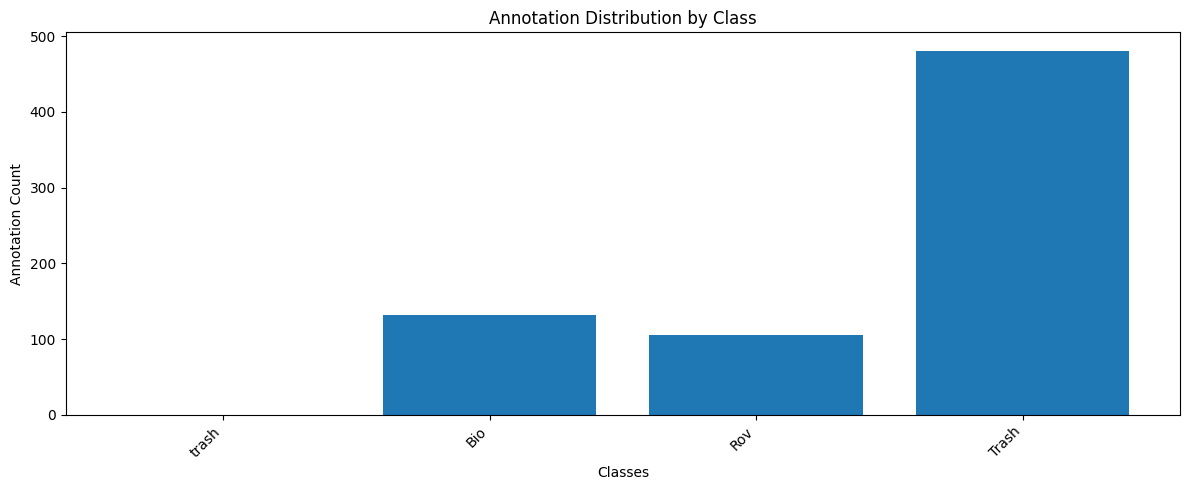


Sample Image Information
Image ID: 0
Image File: 22_jpg.rf.018cec93a69760a1c25414598cc4dabc.jpg
Width: 256
Height: 256

Annotations in Sample Image: 3


In [31]:
# Dataset Exploration and Visualization

from collections import Counter
import matplotlib.pyplot as plt
import random
import os

# 1. Count annotations per class
annotation_counts = Counter(
    annotation["category_id"]
    for annotation in annotation_data["annotations"]
)

category_names = {
    category["id"]: category["name"]
    for category in annotation_data["categories"]
}

names = []
counts = []

for category in annotation_data["categories"]:
    names.append(category["name"])
    counts.append(annotation_counts.get(category["id"], 0))

# 2. Print class distribution
print("CLASS DISTRIBUTION")
print("=" * 40)

for name, count in zip(names, counts):
    print(f"{name}: {count}")

# 3. Plot class distribution
plt.figure(figsize=(12, 5))
plt.bar(names, counts)
plt.title("Annotation Distribution by Class")
plt.xlabel("Classes")
plt.ylabel("Annotation Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 4. Check image dimensions
sample_image = annotation_data["images"][0]

print("\nSample Image Information")
print("=" * 40)
print("Image ID:", sample_image["id"])
print("Image File:", sample_image["file_name"])
print("Width:", sample_image["width"])
print("Height:", sample_image["height"])

# 5. Annotation information
sample_annotations = [
    annotation for annotation in annotation_data["annotations"]
    if annotation["image_id"] == sample_image["id"]
]

print("\nAnnotations in Sample Image:", len(sample_annotations))

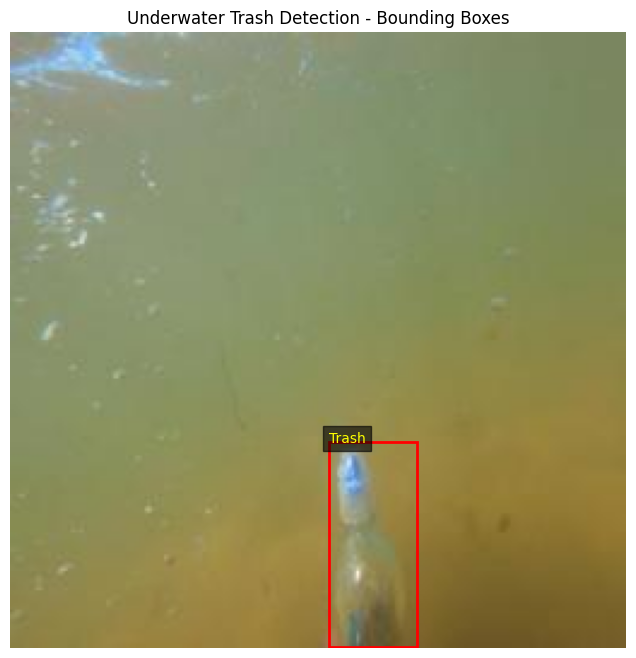

Image: frame_01995_png_jpg.rf.808a1032e3f67c4cb850dbf8bb68f03e.jpg
Objects in Image: 1


In [32]:
# Visualize Images with Bounding Boxes

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os
import random

# Find image folder automatically
possible_folders = [
    "/kaggle/input",
    "/content",
    "."
]

img_path = None

for folder in possible_folders:
    for root, dirs, files_list in os.walk(folder):
        if img_record["file_name"] in files_list:
            img_path = os.path.join(root, img_record["file_name"])
            break
    if img_path:
        break

if img_path is None:
    raise FileNotFoundError(f"Image not found: {img_record['file_name']}")

# Open image
img = Image.open(img_path).convert("RGB")

# Find annotations for this image
img_annotations = [
    ann for ann in annotation_data["annotations"]
    if ann["image_id"] == img_record["id"]
]

# Display image
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)

for ann in img_annotations:
    x, y, w, h = ann["bbox"]

    class_name = category_names[ann["category_id"]]

    rect = patches.Rectangle(
        (x, y), w, h,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

    ax.text(
        x, y, class_name,
        color="yellow",
        bbox=dict(facecolor="black", alpha=0.6)
    )

plt.title("Underwater Trash Detection - Bounding Boxes")
plt.axis("off")
plt.show()

print("Image:", img_record["file_name"])
print("Objects in Image:", len(img_annotations))

In [33]:
# Dataset Train, Validation and Test Split

from sklearn.model_selection import train_test_split
import random

# Get all image IDs
image_ids = [img["id"] for img in annotation_data["images"]]

# First split: 70% training, 30% remaining
train_ids, temp_ids = train_test_split(
    image_ids,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42
)

# Separate images
train_images = [
    img for img in annotation_data["images"]
    if img["id"] in train_ids
]

val_images = [
    img for img in annotation_data["images"]
    if img["id"] in val_ids
]

test_images = [
    img for img in annotation_data["images"]
    if img["id"] in test_ids
]

# Separate annotations
train_annotations = [
    ann for ann in annotation_data["annotations"]
    if ann["image_id"] in train_ids
]

val_annotations = [
    ann for ann in annotation_data["annotations"]
    if ann["image_id"] in val_ids
]

test_annotations = [
    ann for ann in annotation_data["annotations"]
    if ann["image_id"] in test_ids
]

# Display results
print("DATASET SPLIT")
print("=" * 40)

print("Training Images:", len(train_images))
print("Training Annotations:", len(train_annotations))

print("\nValidation Images:", len(val_images))
print("Validation Annotations:", len(val_annotations))

print("\nTesting Images:", len(test_images))
print("Testing Annotations:", len(test_annotations))

print("\nTotal Images:", len(train_images) + len(val_images) + len(test_images))

DATASET SPLIT
Training Images: 331
Training Annotations: 499

Validation Images: 71
Validation Annotations: 102

Testing Images: 71
Testing Annotations: 118

Total Images: 473


In [35]:
!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Pretrained model successfully loaded!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Pretrained model successfully loaded!


In [36]:
!pip install -q ultralytics

from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Pretrained model successfully loaded!")

Pretrained model successfully loaded!


In [37]:
import os

print("Dataset folder:", DATASET_DIR)

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = ' ' * 4 * (level + 1)
    for file in files[:5]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs[:] = []

Dataset folder: /content/Underwater_Trash_Project/Dataset
Dataset/
    README.md
    .gitattributes
    tensorflowOD_format.zip
    YOLO_format.zip
    COCO_format.zip
    .cache/
        huggingface/
            CACHEDIR.TAG
            .gitignore
            trees/
                294d20f28d5adf19b28e9729e96c852e49e42555.json
            download/
                README.md.lock
                YOLO_format.zip.metadata
                .gitattributes.lock
                YOLO_format.zip.lock
                tensorflowOD_format.zip.lock
    COCO_Extracted/
        README.roboflow.txt
        README.dataset.txt
        test/
            vid_000158_frame0000057_jpg.rf.7e06d9cad20245264a1088caddbace32.jpg
            obj0304_frame0000034_jpg.rf.f03bf9d957630b3cbe99b2d8de2ffb64.jpg
            bio0012_frame0000135_jpg.rf.e87510a6cb23abf08779c3d534453da1.jpg
            bio0016_frame0000394_jpg.rf.55ab446536fff80e68a6c029e4705162.jpg
            obj1076_frame0000009_jpg.rf.1409802982dc33745d

In [38]:
import os
import zipfile

DATASET_DIR = "/content/Underwater_Trash_Project/Dataset"
YOLO_ZIP = os.path.join(DATASET_DIR, "YOLO_format.zip")
YOLO_DIR = os.path.join(DATASET_DIR, "YOLO_Extracted")

os.makedirs(YOLO_DIR, exist_ok=True)

if not os.listdir(YOLO_DIR):
    with zipfile.ZipFile(YOLO_ZIP, "r") as zip_ref:
        zip_ref.extractall(YOLO_DIR)

print("YOLO dataset extracted!")

for root, dirs, files in os.walk(YOLO_DIR):
    level = root.replace(YOLO_DIR, '').count(os.sep)
    if level <= 2:
        print(os.path.basename(root),
              "| Images:", sum(f.lower().endswith((".jpg",".png",".jpeg")) for f in files),
              "| Files:", files[:3])

YOLO dataset extracted!
YOLO_Extracted | Images: 0 | Files: ['README.roboflow.txt', 'data.yaml', 'README.dataset.txt']
test | Images: 0 | Files: []
labels | Images: 0 | Files: ['bio0004_frame0000075_jpg.rf.94cef0ce3c78494ebbe8dd96c6a4148f.txt', 'bio0015_frame0000054_jpg.rf.2b35e46fc0f767da21d34445192cd2a1.txt', 'obj1658_frame0001182_jpg.rf.f0e68502ce384265282ce8f98ad96e3a.txt']
images | Images: 473 | Files: ['vid_000158_frame0000057_jpg.rf.7e06d9cad20245264a1088caddbace32.jpg', 'obj0304_frame0000034_jpg.rf.f03bf9d957630b3cbe99b2d8de2ffb64.jpg', 'bio0012_frame0000135_jpg.rf.e87510a6cb23abf08779c3d534453da1.jpg']
valid | Images: 0 | Files: []
labels | Images: 0 | Files: ['frame_00200_png_jpg.rf.1ae22d0162f85fc08585f0505d35a165.txt', 'vid_000331_frame0000187_jpg.rf.32ed52f0560afaea0292cb251e6b2e71.txt', 'obj1655_frame0000183_jpg.rf.fb03e359000c7746f8d6e982da533abf.txt']
images | Images: 1795 | Files: ['obj0313_frame0000015_jpg.rf.f1f1b5ef38bdc66f20cb61fcb7d964a0.jpg', '6_jpeg_jpg.rf.60c6d

In [39]:
# STEP 2: CHECK DATASET CONFIGURATION

import os
import yaml

YOLO_DIR = "/content/Underwater_Trash_Project/Dataset/YOLO_Extracted"

yaml_path = os.path.join(YOLO_DIR, "data.yaml")

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("Original dataset configuration:")
print(data_config)

print("\nDataset folders:")
for split in ["train", "valid", "test"]:
    image_dir = os.path.join(YOLO_DIR, split, "images")
    label_dir = os.path.join(YOLO_DIR, split, "labels")

    print(f"\n{split}:")
    print("Images folder exists:", os.path.exists(image_dir))
    print("Labels folder exists:", os.path.exists(label_dir))
    print("Images:", len(os.listdir(image_dir)) if os.path.exists(image_dir) else 0)
    print("Labels:", len(os.listdir(label_dir)) if os.path.exists(label_dir) else 0)

Original dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['Bio', 'Rov', 'Trash'], 'roboflow': {'workspace': 'utd-0dazj', 'project': 'utd2-hyo53', 'version': 8, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/utd-0dazj/utd2-hyo53/dataset/8'}}

Dataset folders:

train:
Images folder exists: True
Labels folder exists: True
Images: 7308
Labels: 7308

valid:
Images folder exists: True
Labels folder exists: True
Images: 1795
Labels: 1795

test:
Images folder exists: True
Labels folder exists: True
Images: 473
Labels: 473


In [40]:
# PHASE 2: DATASET CONFIGURATION, FINE-TUNING & EVALUATION

!pip install -q ultralytics pyyaml

import os
import yaml
from ultralytics import YOLO

# Dataset paths
YOLO_DIR = "/content/Underwater_Trash_Project/Dataset/YOLO_Extracted"

train_images = os.path.join(YOLO_DIR, "train", "images")
val_images   = os.path.join(YOLO_DIR, "valid", "images")
test_images  = os.path.join(YOLO_DIR, "test", "images")

# Read original YAML
original_yaml = os.path.join(YOLO_DIR, "data.yaml")

with open(original_yaml, "r") as f:
    config = yaml.safe_load(f)

# Create corrected dataset configuration
config["path"] = YOLO_DIR
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

# Save corrected YAML
new_yaml = os.path.join(YOLO_DIR, "dataset.yaml")

with open(new_yaml, "w") as f:
    yaml.dump(config, f)

print("Dataset configuration prepared!")
print(config)

# Load pretrained model
model = YOLO("yolo11n.pt")

# Fine-tuning
training_results = model.train(
    data=new_yaml,
    epochs=30,
    imgsz=640,
    batch=16,
    patience=5,
    workers=2,
    project="/content/Underwater_Trash_Project/Results",
    name="Underwater_Trash_YOLO",
    exist_ok=True
)

print("\nTraining completed!")

# Load best trained model
best_model_path = (
    "/content/Underwater_Trash_Project/Results/"
    "Underwater_Trash_YOLO/weights/best.pt"
)

best_model = YOLO(best_model_path)

# Evaluate on validation dataset
print("\nVALIDATION RESULTS")
validation_results = best_model.val(data=new_yaml, split="val")

# Evaluate on test dataset
print("\nTEST RESULTS")
test_results = best_model.val(data=new_yaml, split="test")

# Save final model
FINAL_MODEL = "/content/Underwater_Trash_Project/Models/best.pt"

os.makedirs(os.path.dirname(FINAL_MODEL), exist_ok=True)
best_model.save(FINAL_MODEL)

print("\nFinal model saved:", FINAL_MODEL)
print("\nPHASE 2 COMPLETED!")

Dataset configuration prepared!
{'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 3, 'names': ['Bio', 'Rov', 'Trash'], 'roboflow': {'workspace': 'utd-0dazj', 'project': 'utd2-hyo53', 'version': 8, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/utd-0dazj/utd2-hyo53/dataset/8'}, 'path': '/content/Underwater_Trash_Project/Dataset/YOLO_Extracted'}
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Underwater_Trash_Project/Dataset/YOLO_Extracted/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dr

In [41]:
# CELL 1: EVALUATION, TESTING AND PREDICTIONS

from ultralytics import YOLO
import os

PROJECT_DIR = "/content/Underwater_Trash_Project"
DATA_YAML = f"{PROJECT_DIR}/Dataset/YOLO_Extracted/dataset.yaml"
BEST_MODEL = f"{PROJECT_DIR}/Results/Underwater_Trash_YOLO/weights/best.pt"

model = YOLO(BEST_MODEL)

# Evaluate on test dataset
metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640
)

print("\n===== TEST RESULTS =====")
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

# Test predictions and save images
test_images = f"{PROJECT_DIR}/Dataset/YOLO_Extracted/test/images"

predictions = model.predict(
    source=test_images,
    imgsz=640,
    conf=0.25,
    save=True,
    project=f"{PROJECT_DIR}/Results",
    name="Test_Predictions"
)

print("\nTest predictions saved successfully!")
print("Model:", BEST_MODEL)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 361.3±177.1 MB/s, size: 8.2 KB)
val: Scanning /content/Underwater_Trash_Project/Dataset/YOLO_Extracted/test/labels.cache... 473 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 473/473 76.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 4.0it/s 7.5s
                   all        473        719      0.915      0.884      0.944      0.722
                   Bio        108        132      0.912      0.944      0.975      0.817
                   Rov         77        106      0.885      0.925      0.944      0.754
                 Trash        369        481       0.95      0.784      0.914      0.595
Speed: 1.7ms preprocess, 4.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved t

In [42]:
# ==========================================
# CELL 2: UPLOAD MODEL TO HUGGING FACE
# ==========================================

!pip install -q huggingface_hub

from huggingface_hub import notebook_login, HfApi, create_repo
import os

# Hugging Face Login
notebook_login()

# Initialize API
api = HfApi()

# Account Details
HF_USERNAME = "Naeema-ab"
REPO_NAME = "underwater-trash-detection"
REPO_ID = f"{HF_USERNAME}/{REPO_NAME}"

# Model Paths
BEST_MODEL = "/content/Underwater_Trash_Project/Results/Underwater_Trash_YOLO/weights/best.pt"

DATA_YAML = "/content/Underwater_Trash_Project/Dataset/YOLO_Extracted/dataset.yaml"

# Check Files
assert os.path.exists(BEST_MODEL), "best.pt not found! Complete training first."
assert os.path.exists(DATA_YAML), "dataset.yaml not found!"

# Create Hugging Face Model Repository
create_repo(
    repo_id=REPO_ID,
    repo_type="model",
    exist_ok=True,
    private=False
)

# Upload Best Trained Model
api.upload_file(
    path_or_fileobj=BEST_MODEL,
    path_in_repo="best.pt",
    repo_id=REPO_ID,
    repo_type="model"
)

# Upload Dataset Configuration
api.upload_file(
    path_or_fileobj=DATA_YAML,
    path_in_repo="dataset.yaml",
    repo_id=REPO_ID,
    repo_type="model"
)

# Upload Model Information
model_info = """
# Underwater Trash Detection

Deep Learning Object Detection Project.

## Model
YOLO11n (Fine-tuned pretrained model)

## Classes
- Bio
- Rov
- Trash

## Training
- Dataset: Underwater Trash Dataset
- Image Size: 640
- Epochs: 30

## Model Weights
best.pt
"""

with open("README.md", "w") as f:
    f.write(model_info)

api.upload_file(
    path_or_fileobj="README.md",
    path_in_repo="README.md",
    repo_id=REPO_ID,
    repo_type="model"
)

print("\n================================")
print("MODEL UPLOADED SUCCESSFULLY!")
print("================================")
print("Username:", HF_USERNAME)
print("Repository:", REPO_ID)
print("Model Link:", f"https://huggingface.co/{REPO_ID}")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...rash_YOLO/weights/best.pt:  10%|9         |  539kB / 5.50MB            

Validating                    :           |   0%            

/usr/local/lib/python3.13/dist-packages/huggingface_hub/hf_api.py:11779: UserWarning: Warnings while validating metadata in README.md:
- empty or missing yaml metadata in repo card
  warnings.warn(f"Warnings while validating metadata in README.md:\n{message}")



MODEL UPLOADED SUCCESSFULLY!
Username: Naeema-ab
Repository: Naeema-ab/underwater-trash-detection
Model Link: https://huggingface.co/Naeema-ab/underwater-trash-detection


In [44]:
# CELL 3: CREATE STREAMLIT APPLICATION AND PROJECT FILES

import os

DEPLOY_DIR = "/content/Underwater_Trash_Project/Deployment"

os.makedirs(DEPLOY_DIR, exist_ok=True)

# APP.PY
app_code = '''
import streamlit as st
from ultralytics import YOLO
from huggingface_hub import hf_hub_download
from PIL import Image

st.set_page_config(page_title="Underwater Trash Detection")

st.title("Underwater Trash Detection")
st.write("Upload an underwater image to detect Bio, Rov and Trash.")

@st.cache_resource
def load_model():
    model_path = hf_hub_download(
        repo_id="YOUR_HUGGINGFACE_USERNAME/underwater-trash-detection",
        filename="best.pt"
    )
    return YOLO(model_path)

model = load_model()

uploaded_file = st.file_uploader(
    "Upload underwater image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Image")

    if st.button("Detect"):
        results = model.predict(image, conf=0.25)
        plotted = results[0].plot()

        st.image(plotted, caption="Detection Results")

        st.write("Detected objects:")
        for box in results[0].boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            class_name = model.names[class_id]

            st.write(f"{class_name}: {confidence:.2f}")
'''

with open(f"{DEPLOY_DIR}/app.py", "w") as f:
    f.write(app_code)

# REQUIREMENTS
requirements = '''
streamlit
ultralytics
huggingface_hub
pillow
'''

with open(f"{DEPLOY_DIR}/requirements.txt", "w") as f:
    f.write(requirements.strip())

# README
readme = '''
# Underwater Trash Detection

Deep learning object detection application using YOLO11n.

## Classes
- Bio
- Rov
- Trash

## Application
Built with Streamlit and hosted model weights on Hugging Face.

## Run
pip install -r requirements.txt
streamlit run app.py
'''

with open(f"{DEPLOY_DIR}/README.md", "w") as f:
    f.write(readme.strip())

print("Deployment files created:")
print(DEPLOY_DIR)

print("app.py")
print("requirements.txt")
print("README.md")

Deployment files created:
/content/Underwater_Trash_Project/Deployment
app.py
requirements.txt
README.md


In [45]:
import os

DEPLOY_DIR = "/content/Underwater_Trash_Project/Deployment"

print("Deployment Files:")
for file in os.listdir(DEPLOY_DIR):
    print(file)

Deployment Files:
README.md
requirements.txt
app.py
